In [ ]:
!pip install drawdata

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 238.0/238.0 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 66.6 MB/s eta 0:00:00


## 运行前必读：这是四分类版（a / b / c / d）**如果跑出来只有 a、b 两类，99% 是下面三个原因之一：**1. **打开错文件**。当前目录下还有 `code_iron_修改后的.ipynb` / `code_iron_2class_fixed.ipynb` /   `code_iron.backup.ipynb`，它们都是**二分类版**（损失函数是 `binary_crossentropy`）。   四分类版只有 **`code_iron.ipynb`** 这一份。   快速确认：搜索文件里有没有 `'c':2` 和 `sparse_categorical_crossentropy`，没有就是旧版。2. **Jupyter 里没重新加载**。我在外部改过这个文件，已在 Jupyter/JupyterLab 里打开的话，   需要先 **Kernel → Restart Kernel**，再 **File → Revert Notebook**（或关掉重开），   然后从第一个单元**依次往下重跑**。只重跑下面几个单元是没用的。3. **画布上只点了两簇**。`ScatterWidget` 默认就有 a/b/c/d 四类（蓝/橙/绿/红四色），   需要手动在上方单选框里切到 c、d 再各点一簇。只画 a/b 的话，   后面所有单元都会「正常执行完」但模型其实只有 2 类 —— 这是最隐蔽的坑，   所以本 notebook 在数据、标签、模型、训练前各加了一道断言，缺类会直接报错停下。

In [ ]:
from drawdata import ScatterWidget

# 四分类：ScatterWidget 默认就提供 a / b / c / d 四个类别（四种颜色）
# 操作：选一个类别 → 在画布上点一簇 → 换下一个类别 → … 四簇都画完再往下执行
# 画布坐标范围固定为 0~1023 × 0~1023
widget = ScatterWidget()
widget

In [ ]:
df = widget.data_as_pandas
df.head()

,x,y,color,label,batch
0,100.957477,324.107128,#1f77b4,a,0
1,99.316705,342.325162,#1f77b4,a,0
2,125.082462,352.252006,#1f77b4,a,0
3,124.415911,333.630984,#1f77b4,a,0
4,103.015264,338.861047,#1f77b4,a,0


(0.0, 1023.0)

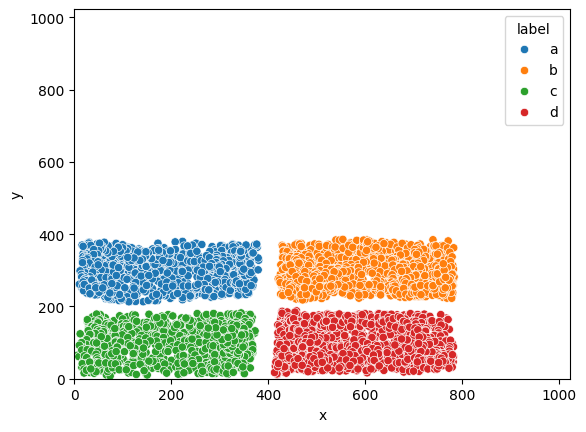

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=df, x='x', y='y', hue='label')
plt.xlim([0,1023])
plt.ylim([0,1023])

In [ ]:
# 四个类别 → 0/1/2/3
label2num = {'a':0, 'b':1, 'c':2, 'd':3}
num2label = {0:'a', 1:'b', 2:'c', 3:'d'}   # 反向映射：MCU 端把 argmax 结果还原成可读类别

df["target"] = df["label"].map(label2num)

df.head()

,x,y,color,label,batch,target
0,100.957477,324.107128,#1f77b4,a,0,0
1,99.316705,342.325162,#1f77b4,a,0,0
2,125.082462,352.252006,#1f77b4,a,0,0
3,124.415911,333.630984,#1f77b4,a,0,0
4,103.015264,338.861047,#1f77b4,a,0,0


In [ ]:
df.tail()

,x,y,color,label,batch,target
4627,751.745354,35.468823,#d62728,d,5,3
4628,735.044077,48.591759,#d62728,d,5,3
4629,760.053536,48.730477,#d62728,d,5,3
4630,772.603711,29.119460,#d62728,d,5,3
4631,751.241091,44.599161,#d62728,d,5,3


In [ ]:
# ★ 自检 1（最关键）：确认画布上真的有 4 类
# 常见翻车方式：只画了 a/b 两簇就往下跑 —— 后面所有单元都会「正常执行」，
# 模型其实只学了 2 类，而 softmax(4) 也不会报错，非常隐蔽。所以这里直接断言拦死。
present = set(df['label'].unique())
missing = sorted(set(label2num) - present)
assert not missing, (
    f'画布上缺少类别 {missing}！回到上面的画布，'
    f'把 a/b/c/d 四类各点一簇再来。（当前只有 {sorted(present)}）'
)

counts = df['label'].value_counts().sort_index()
print('各类样本数:'); print(counts.to_string())
print('类别数:', len(counts), '（必须为 4）')
assert len(counts) == 4, f'只有 {len(counts)} 类，请补齐'
assert counts.min() >= 10, f'有类别样本过少（最少 {counts.min()} 个），建议每类 ≥ 15 个，否则该类学不出来'

各类样本数:
label
a    1080
b    1179
c    1005
d    1368
类别数: 4 （必须为 4）


In [ ]:
import numpy as np

# 构造特征矩阵与标签向量
X = df[["x","y"]].to_numpy()          # shape = (n_samples, 2)

# sparse_categorical_crossentropy 要求 y 是「整数类别号」0/1/2/3，不要 one-hot、不要 float
y = df['target'].astype('int64').to_numpy()

# ★ 自检 2：标签里必须真的出现 0/1/2/3 四个值（缺哪个说明那类一个点都没画）
uniq = np.unique(y)
print('X:', X.shape, '| y:', y.shape, y.dtype, '| 出现的类别号:', uniq, '| 各类样本数:', np.bincount(y))
assert set(uniq) == {0, 1, 2, 3}, f'类别号应为 0/1/2/3，实际是 {uniq}'

X: (4632, 2) | y: (4632,) int64 | 出现的类别号: [0 1 2 3] | 各类样本数: [1080 1179 1005 1368]


In [ ]:
from sklearn.model_selection import train_test_split

# test_size=0.2（80% 训练 / 20% 测试）
# stratify=y：按类别比例分层抽样，四分类时尤其重要，否则某类可能一个测试样本都没有
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=47,
    shuffle=True,
    stratify=y,
)

print('train:', X_train.shape, 'test:', X_test.shape)
print('训练集各类占比:', np.bincount(y_train) / len(y_train))
print('测试集各类占比:', np.bincount(y_test) / len(y_test))

train: (3705, 2) test: (927, 2)
训练集各类占比: [0.23319838 0.25452092 0.21700405 0.29527665]
测试集各类占比: [0.23300971 0.25458468 0.21682848 0.29557713]


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# 正确做法：只在训练集上 fit 统计量，再统一 transform 训练/测试集，避免数据泄漏
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# 训练集的均值与标准差 —— 它们属于「模型的一部分」
# 嵌入式端推理前必须用同样的两个数做归一化，否则预测结果全错
scaler.mean_, scaler.scale_

(array([413.50968853, 195.44103735]), array([228.39946806, 109.00824408]))

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# 四分类改造的核心：
#   二分类 = Dense(1, sigmoid)；四分类 = Dense(4, softmax)
#   softmax 保证 4 个输出都为正且和为 1，可以直接当成四类的概率
# 四类的决策边界比二类复杂，隐藏层从 8/4 加到 16/16，避免欠拟合（约 388 个参数，MCU 仍然扛得住）
model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))      # 2 个特征：x, y
model.add(Dense(16, activation='relu'))
model.add(Dense(16, activation='relu'))
model.add(Dense(4, activation='softmax'))        # 4 个类别 → 4 个概率

# ★ 自检 3：输出层必须是 4，写错成 1 的话下面训练也不会报错，但结果就是二分类
assert model.output_shape[-1] == 4, f'输出层维度应为 4，实际是 {model.output_shape[-1]}'
print('输出层维度:', model.output_shape[-1], '（= 类别数）')

model.summary()

输出层维度: 4 （= 类别数）


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 388 (1.52 KB)

 Trainable params: 388 (1.52 KB)

 Non-trainable params: 0 (0.00 B)

### 为什么必须改这三处：输出层 / 损失函数 / 判据二分类用 **1 个 sigmoid 输出 + `binary_crossentropy` + 阈值 0.5**；换成四类后如果只改标签映射而保留原结构，`Dense(1)` 根本表达不了四个类别，loss 会卡住不降。正确组合是 **4 个 softmax 输出 + `sparse_categorical_crossentropy` + `argmax`**：| | 二分类 | 四分类 ||---|---|---|| 输出层 | `Dense(1, sigmoid)` | `Dense(4, softmax)` || 输出含义 | 属于类别 1 的概率 | 四个类别的概率（和为 1） || 损失函数 | `binary_crossentropy` | `sparse_categorical_crossentropy` || y 形态 | 0 / 1 | 0 / 1 / 2 / 3（整数，非 one-hot） || 判据 | `> 0.5` | `argmax` |> 若你坚持用 `categorical_crossentropy`，就得先把 y 变成 one-hot> （`tf.keras.utils.to_categorical(y, 4)`），推断时再对输出做 `argmax`。本文件走 `sparse_` 路线，省一步。

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

# 关键：损失函数换成 sparse_categorical_crossentropy
#   sparse_  版本接受整数类别号 y（0/1/2/3）—— 就是我们现在的数据形态
#   categorical_crossentropy 则要求 y 先 one-hot 成 (n, 4)，两者别混用
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# ★ 自检 4：训练前最后一道岗
#   y_train 里必须四类齐全，否则 stratify 之后模型永远见不到某个类
train_cls = set(np.unique(y_train))
assert train_cls == {0, 1, 2, 3}, f'训练集里只有 {sorted(train_cls)}，缺的类没画点或样本太少'
print('训练集类别:', sorted(train_cls))

early_stop = EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True)

history = model.fit(X_train, y_train,
                    epochs=300,
                    batch_size=32,
                    validation_data=(X_test, y_test),
                    callbacks=[early_stop],
                    verbose=1)

print('实际训练轮数:', len(history.history['loss']))

训练集类别: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
Epoch 1/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6157 - loss: 1.1217 - val_accuracy: 0.9018 - val_loss: 0.7637
Epoch 2/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9816 - loss: 0.4799 - val_accuracy: 1.0000 - val_loss: 0.2679
Epoch 3/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 0.1841 - val_accuracy: 1.0000 - val_loss: 0.1216
Epoch 4/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 0.0950 - val_accuracy: 1.0000 - val_loss: 0.0704
Epoch 5/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 0.0587 - val_accuracy: 1.0000 - val_loss: 0.0465
Epoch 6/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 0.0400 - val_accuracy: 1.0000 - val_loss: 0.0321
Epoch 7/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 0.0288 - val_accuracy: 1.0000 - val_loss: 0.0246
Epoch 8/300
116/116 ━━━━━━━━━━━━━━━━━

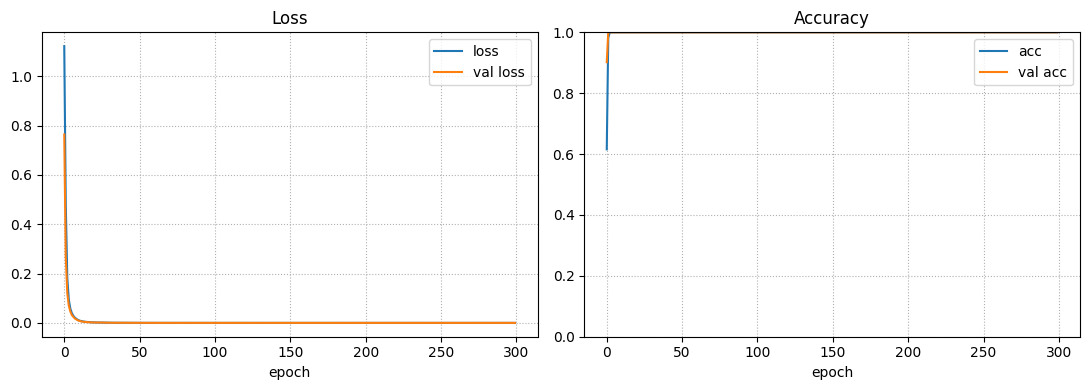

In [ ]:
import matplotlib.pyplot as plt

# 修复：原代码把 loss(量纲可能是 0.7) 和 accuracy(0~1) 画在同一坐标系里，
#       量纲不同不可比。这里拆成左右两张子图。
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history.history['loss'], label='loss')
axes[0].plot(history.history['val_loss'], label='val loss')
axes[0].set_title('Loss')
axes[0].set_xlabel('epoch'); axes[0].legend(); axes[0].grid(ls=':')

axes[1].plot(history.history['accuracy'], label='acc')
axes[1].plot(history.history['val_accuracy'], label='val acc')
axes[1].set_title('Accuracy')
axes[1].set_ylim([0, 1]); axes[1].set_xlabel('epoch'); axes[1].legend(); axes[1].grid(ls=':')

plt.tight_layout()

Text(0.5, 1.0, 'Decision regions (a/b/c/d)')

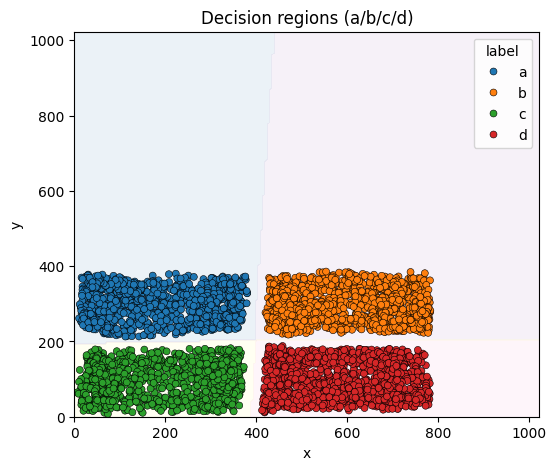

In [ ]:
# 画决策区域：四分类时模型的输出是每个网格点的 4 个概率，取最大的那个作为该点类别
xx, yy = np.meshgrid(np.linspace(0, 1023, 200), np.linspace(0, 1023, 200))
grid = scaler.transform(np.c_[xx.ravel(), yy.ravel()])

probs = model.predict(grid, verbose=0)                    # shape = (40000, 4)
Z = np.argmax(probs, axis=1).reshape(xx.shape)            # 每个网格点归属的类别号

plt.figure(figsize=(6, 5))
# 背景色块只表示「区域归属」，与散点颜色是两套配色，不用一一对应
plt.contourf(xx, yy, Z, levels=np.arange(-0.5, 4.5, 1), alpha=0.25, cmap='Pastel1')
sns.scatterplot(data=df, x='x', y='y', hue='label', edgecolor='k', s=25)
plt.xlim([0, 1023]); plt.ylim([0, 1023])
plt.title('Decision regions (a/b/c/d)')

test loss / acc = [6.429842214217274e-10, 1.0]
accuracy = 1.0


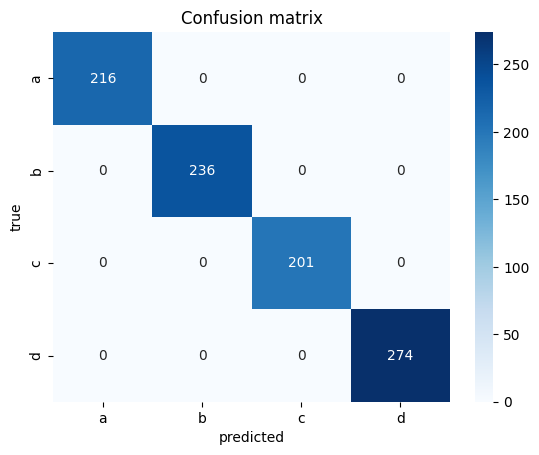

              precision    recall  f1-score   support

           a       1.00      1.00      1.00       216
           b       1.00      1.00      1.00       236
           c       1.00      1.00      1.00       201
           d       1.00      1.00      1.00       274

    accuracy                           1.00       927
   macro avg       1.00      1.00      1.00       927
weighted avg       1.00      1.00      1.00       927



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

proba = model.predict(X_test, verbose=0)             # shape = (n_test, 4)
y_pred = np.argmax(proba, axis=1)                   # 关键：四分类用 argmax 取最大概率的类别，不再是 >0.5

names = [num2label[i] for i in range(4)]
print('test loss / acc =', model.evaluate(X_test, y_test, verbose=0))
print('accuracy =', accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=names, yticklabels=names)
plt.xlabel('predicted'); plt.ylabel('true'); plt.title('Confusion matrix')
plt.show()

# 四分类必须看 report：能看出到底是哪两类在互相混淆
print(classification_report(y_test, y_pred, target_names=names, labels=[0, 1, 2, 3]))

## Export model to tensorflow lite

In [ ]:
import tensorflow as tf

# Keras → TFLite，默认导出 float32 全精度模型
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# 修复：补充量化选项说明。跑在 MCU 上时建议打开（注释取消即可）：
#   converter.optimizations = [tf.lite.Optimize.DEFAULT]                       # 权重量化，体积约缩小 4 倍
#   converter.representative_dataset = lambda: (                                # int8 全量化需要代表性样本
#       [np.array(scaler.transform(X_train[i:i+1]), dtype=np.float32) for i in range(100)]
#   )
#   converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
#   converter.inference_input_type = tf.int8
#   converter.inference_output_type = tf.int8
# 注意：一旦量化，输入也要按同样的 scale/zero_point 量化，别和 StandardScaler 的 float 预处理混在一起。

tflite_model = converter.convert()

with open("model.tflite", 'wb') as f:
    f.write(tflite_model)

print('tflite 体积: %.1f KB' % (len(tflite_model) / 1024))

Saved artifact at '/tmp/tmp6l2t7njt'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 2), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  137950330986832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137950330987792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137950330987024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137950330988560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137950330987408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137950330989520: TensorSpec(shape=(), dtype=tf.resource, name=None)
tflite 体积: 3.6 KB


In [ ]:
def convert_to_c_array(tflite_model, filename):
    with open(tflite_model, 'rb') as f:
        tflite_data = f.read()

    with open(filename, 'w') as f:
        f.write('#include <cstdint>\n')
        # 修复：加 alignas(16)。TFLite Micro 要求模型缓冲区至少 8 字节对齐（建议 16），
        #       否则 GetModel() 可能返回 nullptr 或运行到一半崩掉。
        f.write(f'const unsigned char {tflite_model.replace(".tflite", "")}_tflite[] alignas(16) = {{\n')

        for i, byte in enumerate(tflite_data):
            if i % 12 == 0:
                f.write('\n  ')
            f.write(f'0x{byte:02x}, ')

        f.write('\n};\n')
        f.write(f'const unsigned int {tflite_model.replace(".tflite", "")}_tflite_len = {len(tflite_data)};\n')

# Example usage
convert_to_c_array('model.tflite', 'model.h')

In [ ]:
# 用 TFLite Interpreter 回测，确认转换后的模型与 Keras 原模型输出一致
interpreter = tf.lite.Interpreter(model_path="model.tflite")
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()
print('input :', input_details[0]['shape'], input_details[0]['dtype'])
print('output:', output_details[0]['shape'], output_details[0]['dtype'], '（4 个类别的概率）')

sample = scaler.transform(np.array([[400, 420]])).astype(np.float32)
interpreter.set_tensor(input_details[0]['index'], sample)
interpreter.invoke()
tflite_out = interpreter.get_tensor(output_details[0]['index'])

keras_out = model.predict(sample, verbose=0)
print('keras  概率:', keras_out.round(4), '→ 类别', num2label[int(np.argmax(keras_out, axis=1)[0])])
print('tflite 概率:', tflite_out.round(4), '→ 类别', num2label[int(np.argmax(tflite_out, axis=1)[0])])
print('最大偏差:', np.abs(keras_out - tflite_out).max())

input : [1 2] <class 'numpy.float32'>
output: [1 4] <class 'numpy.float32'> （4 个类别的概率）
keras  概率: [[0.9939 0.0061 0.     0.    ]] → 类别 a
tflite 概率: [[0.9939 0.0061 0.     0.    ]] → 类别 a
最大偏差: 5.9604645e-08


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
import numpy as np

# 修复：原代码把下面打印出来的值人工抄进下一个单元的推理公式里，
#       一旦重新训练/改动切分比例就会静默失配。这里直接导出成 C 头文件，让固件和笔记本同源。
print('mean :', scaler.mean_)
print('scale:', scaler.scale_)

with open('scaler.h', 'w') as f:
    f.write('#pragma once\n')
    f.write(f'// MCU 端推理前必须先做同样的归一化: (raw - MEAN) / SCALE\n')
    f.write(f'#define INPUT_MEAN  {{{scaler.mean_[0]:.8f}f, {scaler.mean_[1]:.8f}f}}\n')
    f.write(f'#define INPUT_SCALE {{{scaler.scale_[0]:.8f}f, {scaler.scale_[1]:.8f}f}}\n')

print(open('scaler.h').read())

mean : [413.50968853 195.44103735]
scale: [228.39946806 109.00824408]
#pragma once
// MCU 端推理前必须先做同样的归一化: (raw - MEAN) / SCALE
#define INPUT_MEAN  {413.50968853f, 195.44103735f}
#define INPUT_SCALE {228.39946806f, 109.00824408f}



In [ ]:
# 推理：统一交给 scaler，保证与训练时完全一致（不要手抄 mean/scale）
val1 = 400   # 原始 x 坐标
val2 = 420   # 原始 y 坐标

array1 = scaler.transform(np.array([[val1, val2]]))
probs = model.predict(array1, verbose=0)          # shape (1, 4)，四个类别的概率，和为 1

pred = int(np.argmax(probs, axis=1)[0])           # 关键：取概率最大的类别，不再是 >0.5 判 0/1
print('各类概率:', {num2label[i]: round(float(p), 4) for i, p in enumerate(probs.ravel())})
print('预测类别 =', pred, '->', num2label[pred])

各类概率: {'a': 0.9939, 'b': 0.0061, 'c': 0.0, 'd': 0.0}
预测类别 = 0 -> a


## 修改说明

### A. 通用问题修复（二分类时期就已修好的部分）

| # | 问题 | 修法 |
|---|---|---|
| 1 | `train_size=0.2` 只有 20% 数据参与训练 | 改 `test_size=0.2` + `stratify=y`，切分后打印各类占比 |
| 2 | `epochs=10` 必欠拟合 | 上限 300 轮 + `EarlyStopping(patience=30, restore_best_weights=True)` |
| 3 | `scaler.mean_/scale_` 被手抄进推理公式 | 改用 `scaler.transform()`，并自动导出 `scaler.h` |
| 4 | C 数组无对齐声明 | 加 `alignas(16)` |
| 5 | TFLite 未量化 | 注释里给出 `Optimize.DEFAULT` / int8 全量化写法 |
| 6 | loss 与 accuracy 共用 y 轴 | 拆成两张子图 |
| 7 | `y` 是 pandas Series | 改 `df['target'].to_numpy()` |

### B. 二分类 → 四分类的改造点

| 环节 | 二分类 | 四分类 | 原因 |
|---|---|---|---|
| 标签 | `{'a':0,'b':1}` | `{'a':0,'b':1,'c':2,'d':3}` | 类别数变了 |
| 输出层 | `Dense(1, sigmoid)` | **`Dense(4, softmax)`** | sigmoid 只能表达「是/否」，四类需要 4 个输出且和为 1 |
| 损失函数 | `binary_crossentropy` | **`sparse_categorical_crossentropy`** | 多分类必须用 categorical 系列；`sparse_` 版本直接吃整数类别号 |
| 标签类型 | 0/1 | 0/1/2/3 的 `int64` | `sparse_` 版本不接受 one-hot |
| 隐藏层 | 8 → 4 | 16 → 16 | 四类边界更复杂，容量太小会欠拟合 |
| 预测判据 | `prob > 0.5` | **`np.argmax(probs)`** | 输出是 4 个概率，取最大的 |
| 评估 | accuracy | accuracy + 4×4 混淆矩阵 + classification_report | 要看清是哪两类互相混淆 |
| 决策区域 | 画 0.5 概率线 | 按 `argmax` 填 4 色区域 | 同上 |

### C. 部署到 MCU 时记住

1. `scaler.h` 里的 `INPUT_MEAN` / `INPUT_SCALE` 与 `model.tflite` **必须配套更新**，重新训练就要一起换。
2. MCU 端推理结果现在是一个 **长度 4 的概率数组**，固件里要做 `argmax` 才是类别号，再用 `num2label` 还原成 a/b/c/d。
3. 模型缓冲区要 8/16 字节对齐（本文件已加 `alignas(16)`）。